#  Predicting Student Exam Performance

### objective :
Build a model to predict a student's final math exam score (or grade) based on various factors like study habits, demographics, and school characteristics. This is a regression problem

In [4]:
# importation libraries :
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

# Set option to display all columns
pd.set_option('display.max_columns', None)

In [5]:
df = pd.read_csv('student-mat.csv' , sep=';')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## EDA (exploration analyse data)

#### Analyse de Forme :
* identify target  => G3 (final grade)
* num of ligne & colonne  =>  (395, 33)
* type des variables(features)  => we have categorialle and numerical features(int/float)
* identifiant Nan (missing values)  => 0 Nan
  
+ elimine some columns that arent important like:
school (GP/MS) ,reason,guardian,Medu, Fedu, Mjob, Fjob
#### Analyse de Forme :
* Visualisation de target  => # most student grade G3 :btw[8 & 14]
*  Comprehension des diff var (seperatly)  => 
*   Visualisation des relations entre features with target and with each others  => we notice that G1 & G2 had very strong relation with G3(target)
*   Identification des outliers  =>failure columns 28outliers  # we can see most data is in 0 make it high in outliers

In [6]:
df.shape 

(395, 33)

In [7]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [15]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

<Figure size 1200x1000 with 0 Axes>

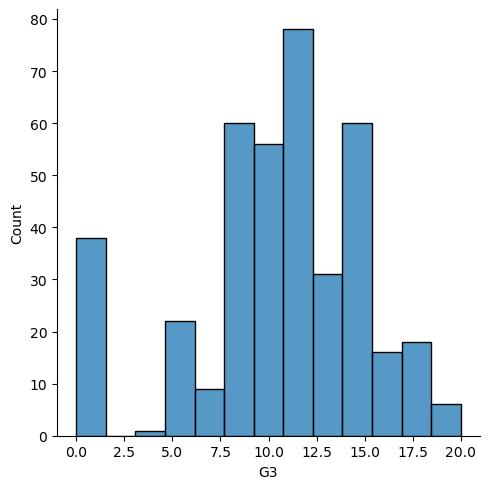

In [16]:
plt.figure(figsize=(12,10))
sns.displot(df['G3'])

<Axes: ylabel='G3'>

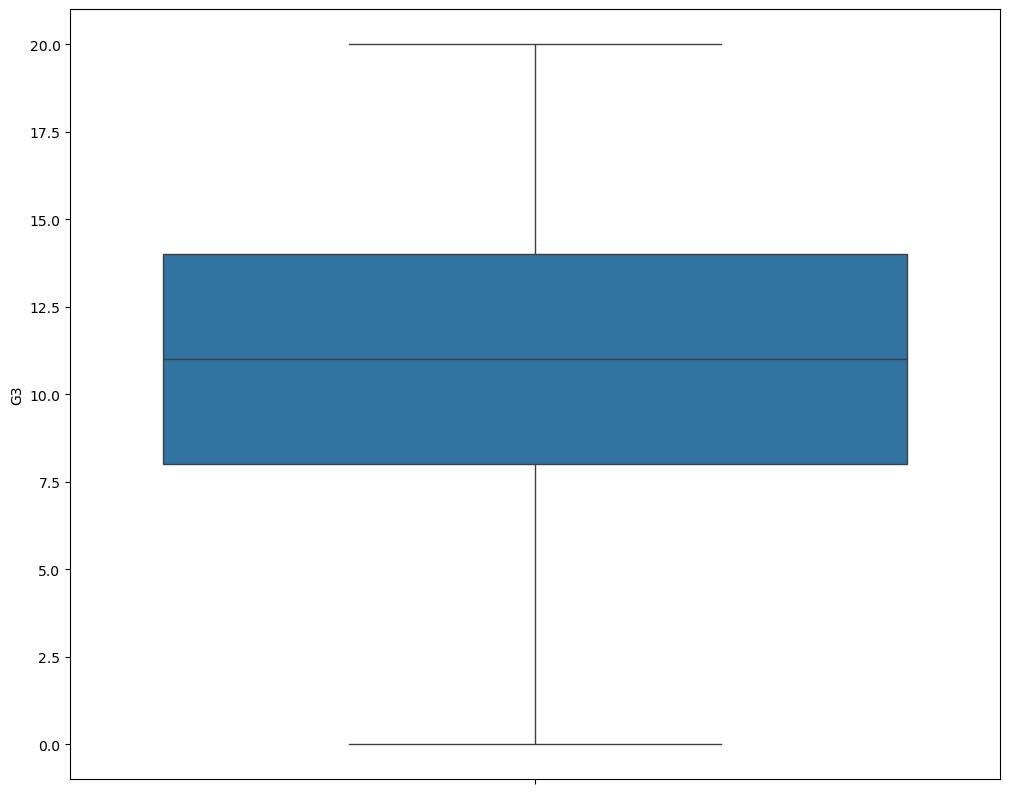

In [17]:
plt.figure(figsize=(12,10))
sns.boxplot(df['G3']) # most stident grade btw 8 & 14

In [19]:
# elimine unessesary columns (school (GP/MS) ,reason,guardian,Medu, Fedu, Mjob, Fjob):
df = df.drop(['school', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian'],axis=1)


In [20]:
df.head()

,sex,age,address,famsize,Pstatus,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,F,18,U,GT3,A,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,F,17,U,GT3,T,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,F,15,U,LE3,T,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,F,15,U,GT3,T,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,F,16,U,GT3,T,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [22]:
df.shape

(395, 26)

In [24]:
df.nunique()

sex            2
age            8
address        2
famsize        2
Pstatus        2
traveltime     4
studytime      4
failures       4
schoolsup      2
famsup         2
paid           2
activities     2
nursery        2
higher         2
internet       2
romantic       2
famrel         5
freetime       5
goout          5
Dalc           5
Walc           5
health         5
absences      34
G1            17
G2            17
G3            18
dtype: int64

In [29]:
df['health'].unique()

array([3, 5, 1, 2, 4])

In [30]:
df.describe()

,age,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


<Axes: >

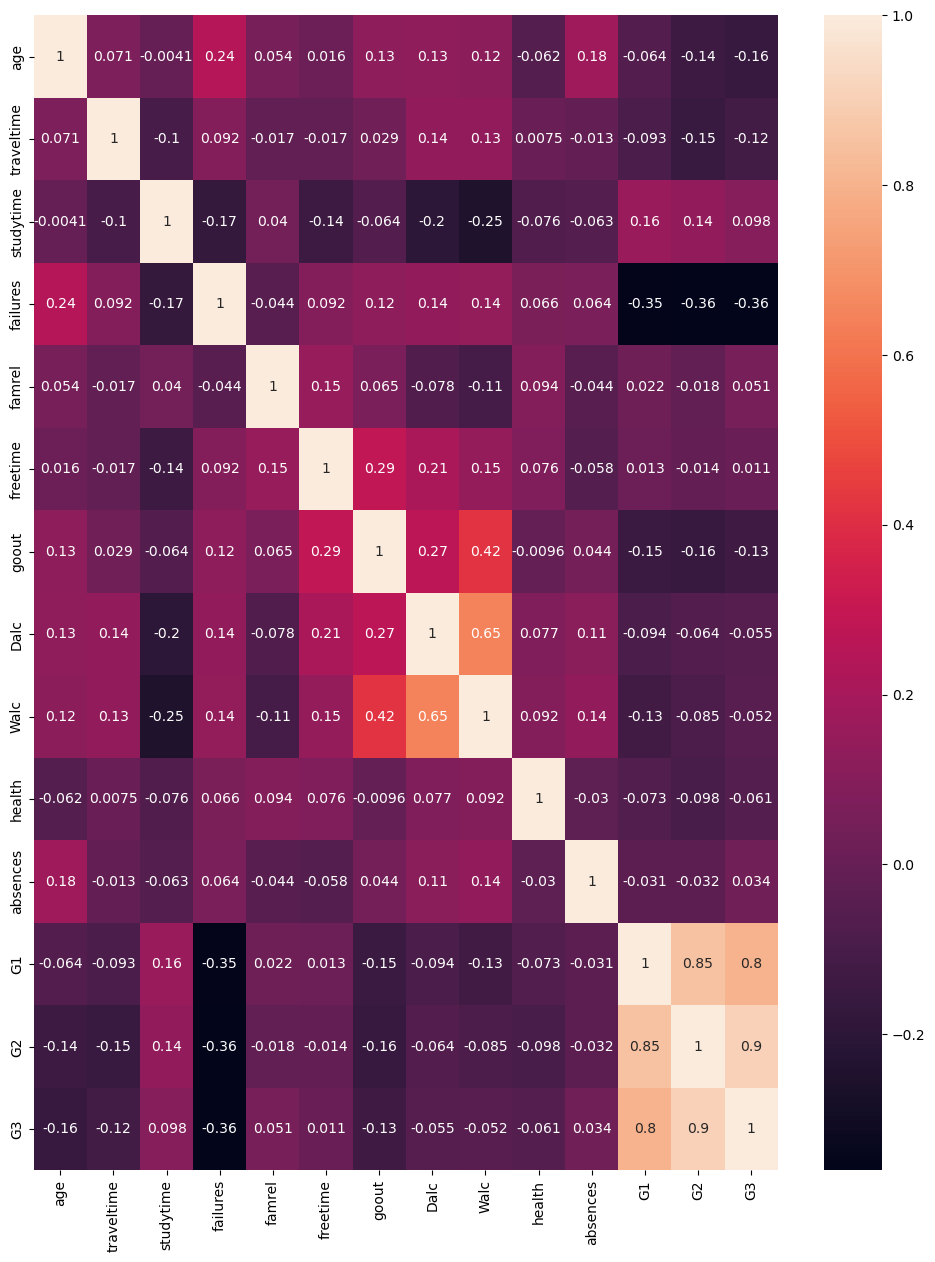

In [36]:
# correlation btw features with each others n target
plt.figure(figsize=(12,15))
sns.heatmap(df[['age','traveltime','studytime','failures','famrel','freetime','goout','Dalc','Walc','health','absences','G1','G2','G3']].corr(),annot=True)

<Figure size 1200x1000 with 0 Axes>

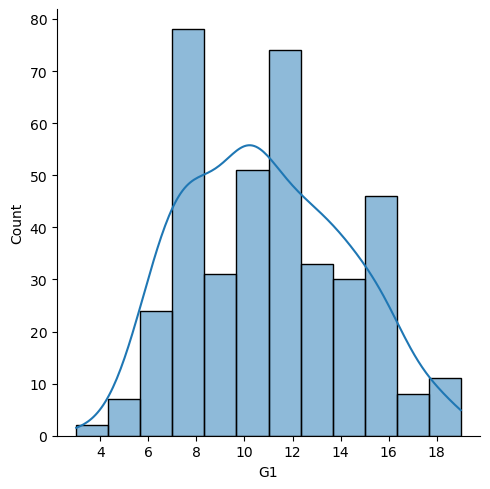

In [45]:
plt.figure(figsize=(12,10))
sns.displot(df['G1'], kde=True)

<Figure size 1200x1000 with 0 Axes>

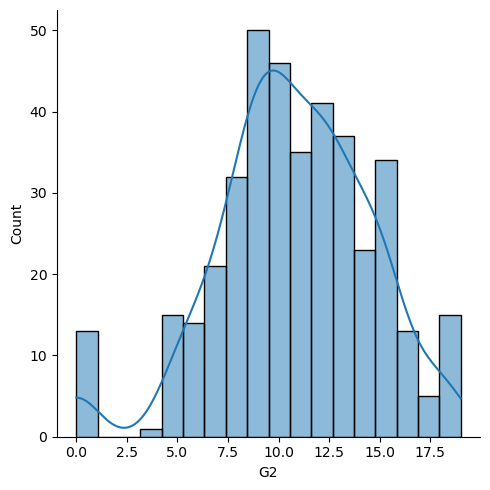

In [44]:
plt.figure(figsize=(12,10))
sns.displot(df['G2'], kde=True)

In [39]:
df.columns

Index(['sex', 'age', 'address', 'famsize', 'Pstatus', 'traveltime',
       'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime',
       'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

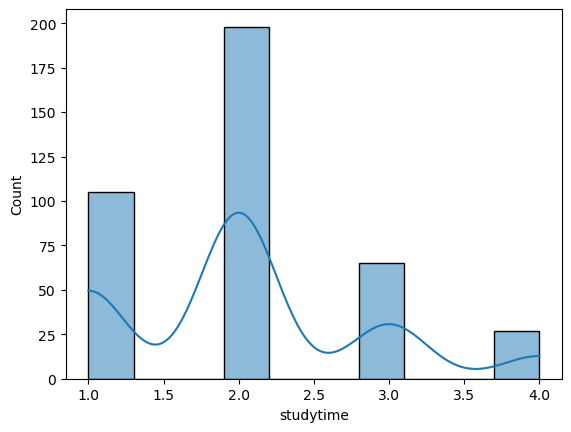

In [43]:
sns.histplot(df['studytime'], bins=10, kde=True)
plt.show()

studytime is 1 or 2 or 3 or 4

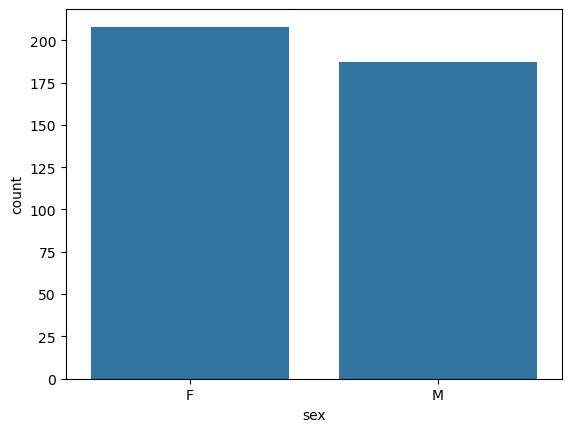

In [46]:
sns.countplot(x='sex', data=df) 
plt.show() 

female are more than male

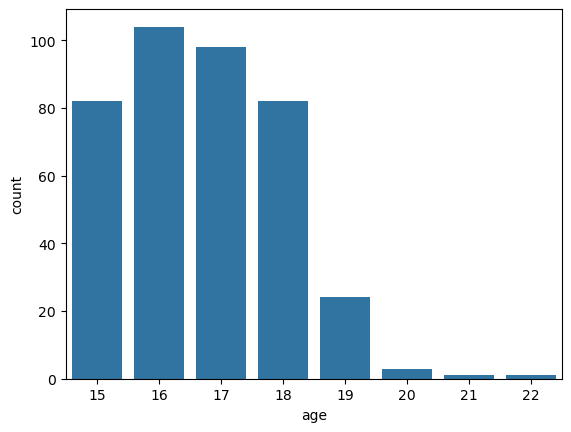

In [47]:
sns.countplot(x='age', data=df) 
plt.show() 

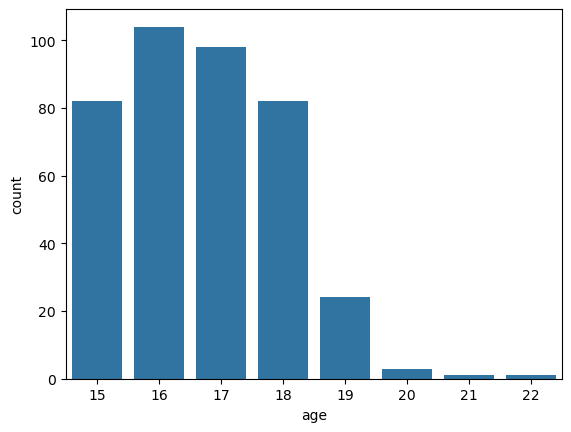

In [50]:
sns.countplot(x='age', data=df) 
plt.show() 

most students are teenager btw 15-18 there are some 20 students (rare) 

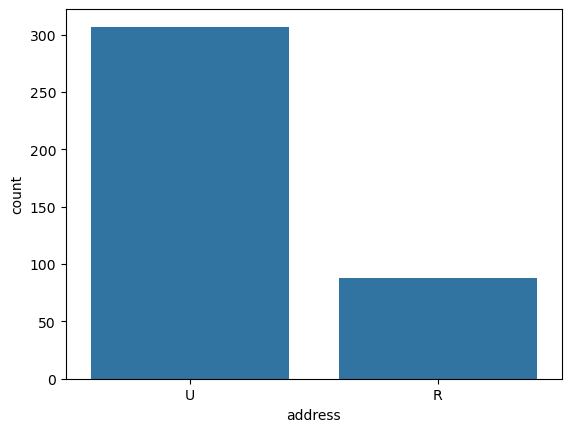

In [52]:
sns.countplot(x='address', data=df) 
plt.show() 

most of student live in urbane than rurale

In [53]:
# Visualize Relationships Between Two Features

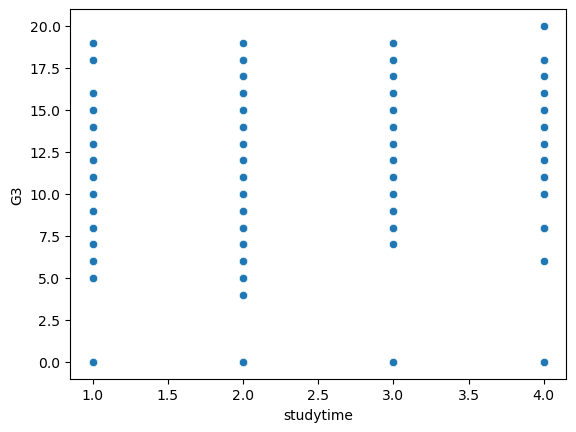

In [54]:
# Example: studytime vs final grade
sns.scatterplot(x='studytime', y='G3', data=df)
plt.show()


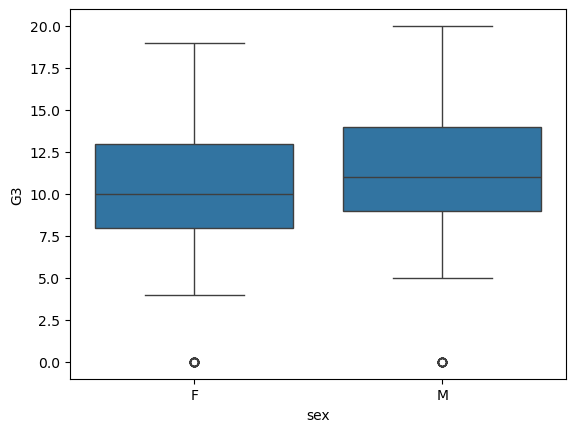

In [55]:
# Example: sex vs final grade 
sns.boxplot(x='sex', y='G3', data=df)
plt.show()

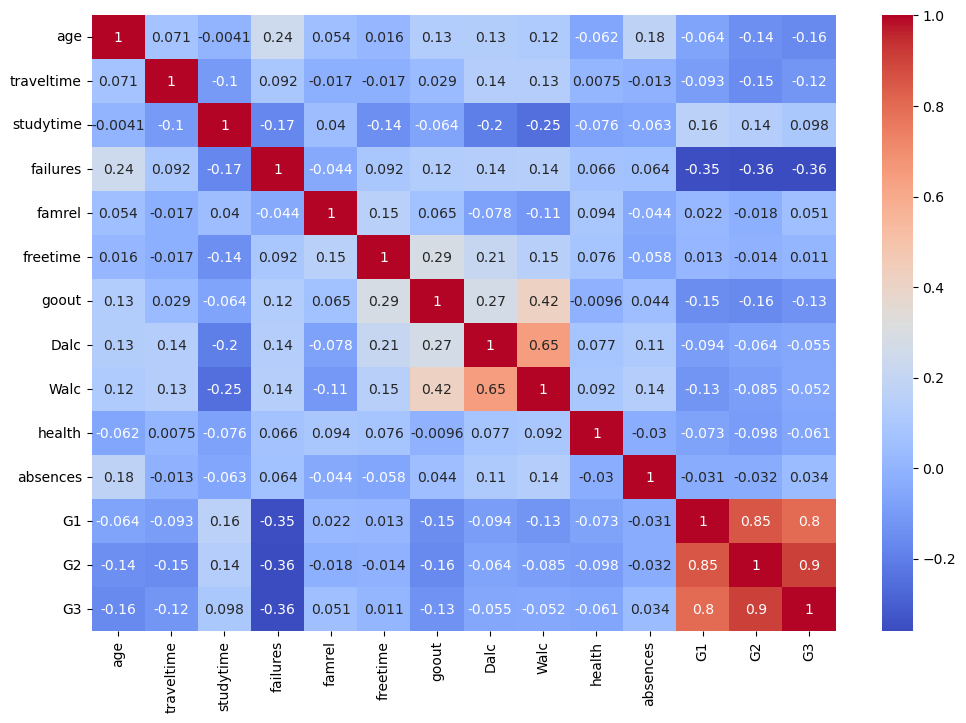

In [56]:
# Select numeric columns
numeric_cols = ['age','traveltime','studytime','failures','famrel','freetime',
                'goout','Dalc','Walc','health','absences','G1','G2','G3']

# Correlation matrix
corr = df[numeric_cols].corr()

# Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()


C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


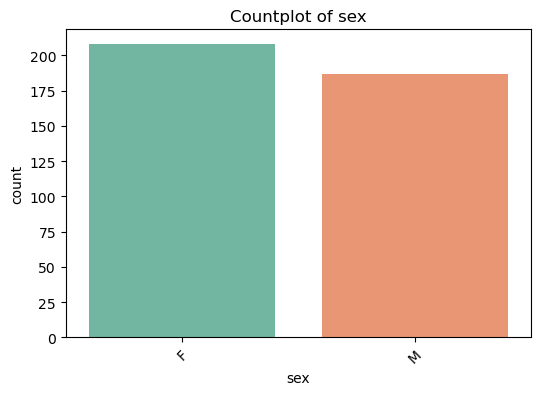

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


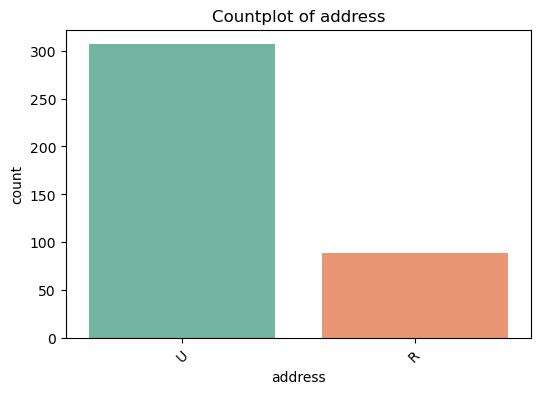

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


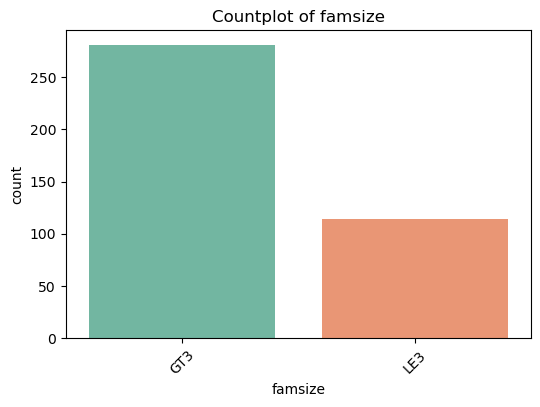

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


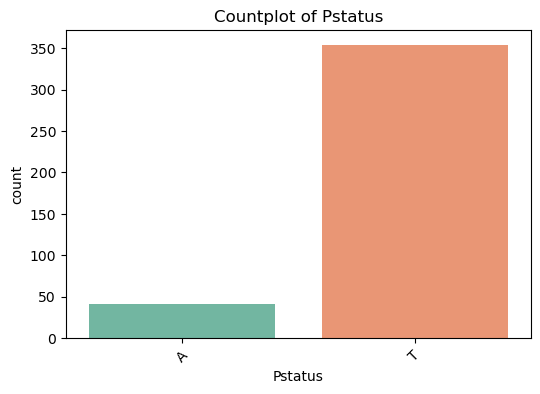

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


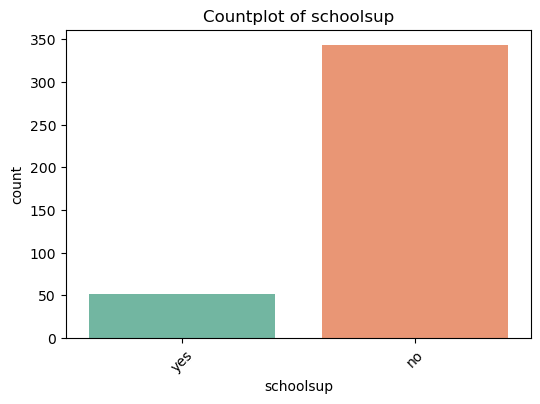

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


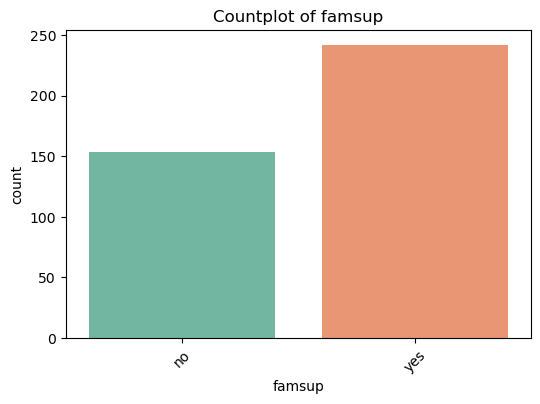

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


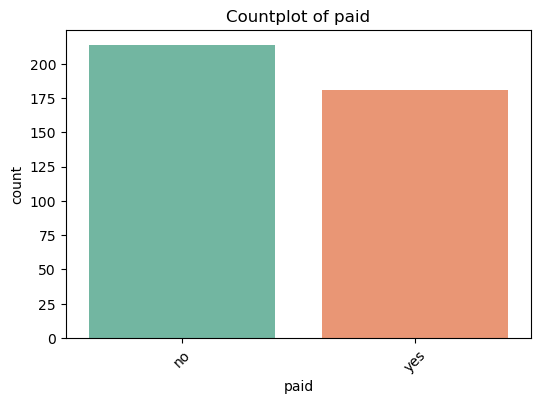

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


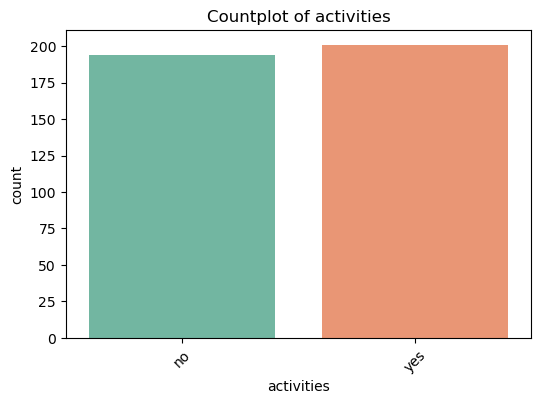

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


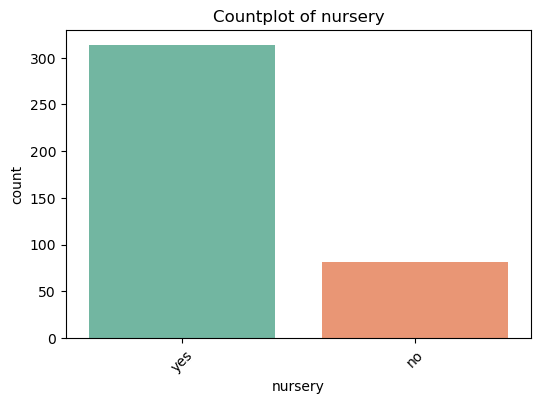

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


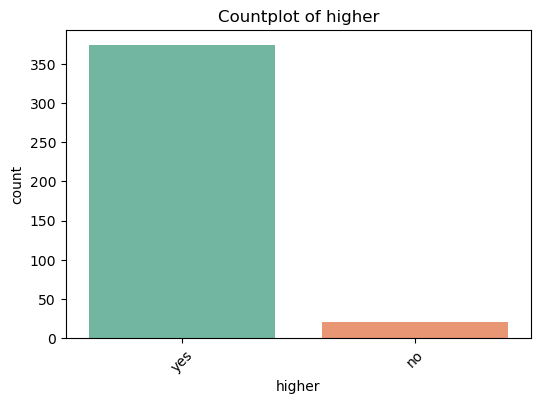

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


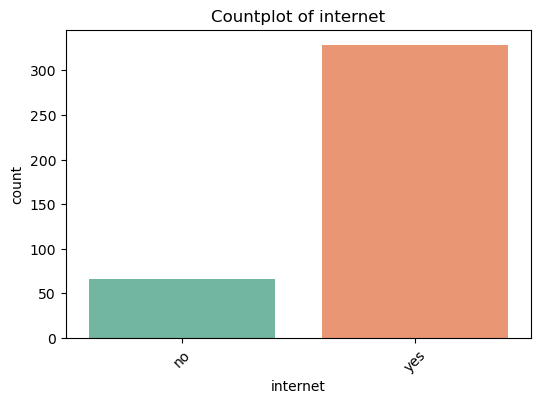

C:\Users\hp\AppData\Local\Temp\ipykernel_20860\2128240112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette="Set2")


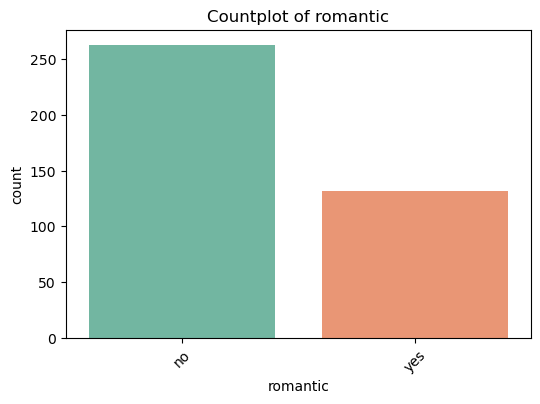

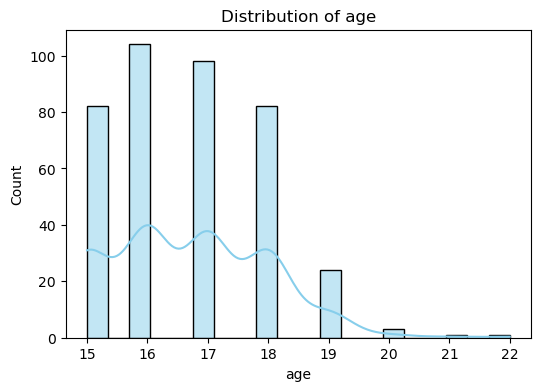

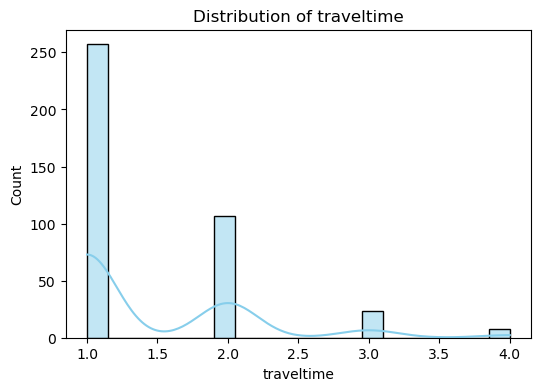

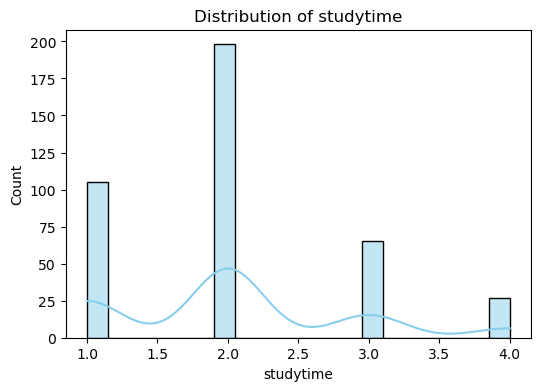

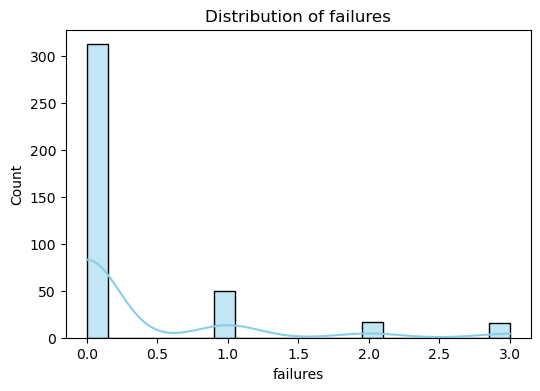

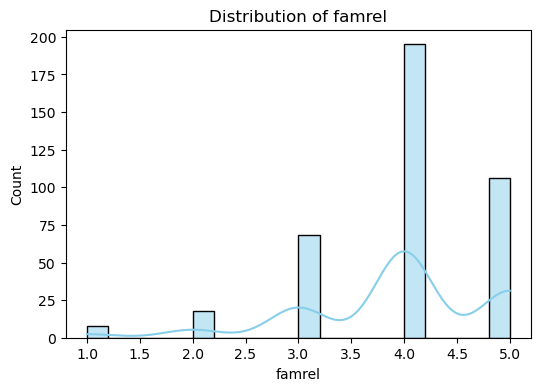

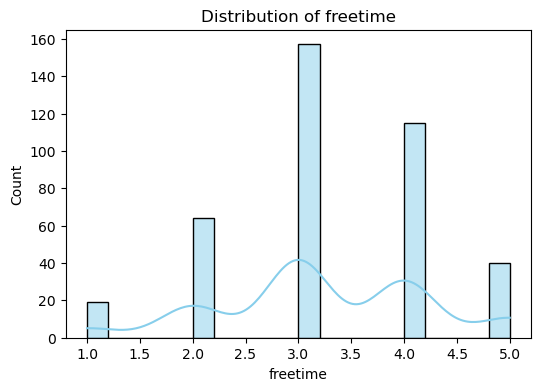

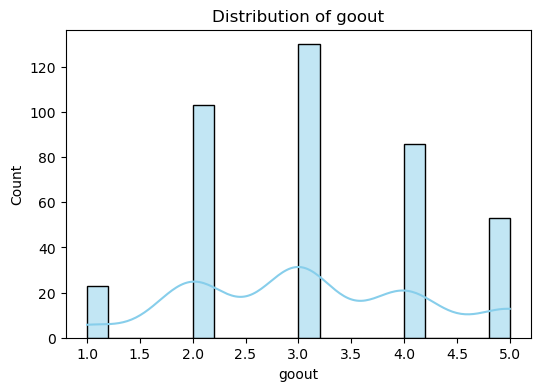

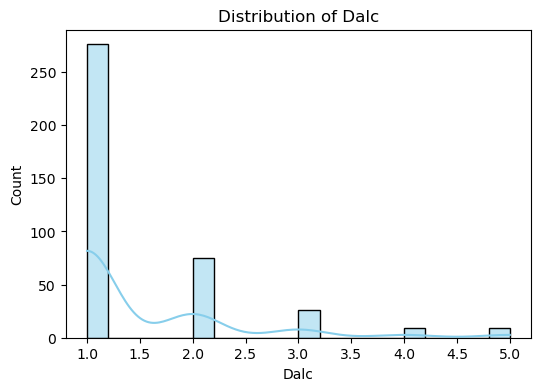

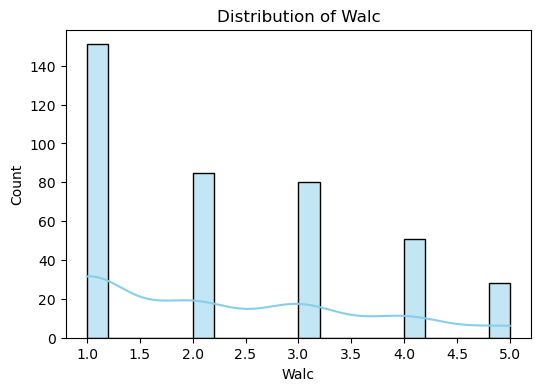

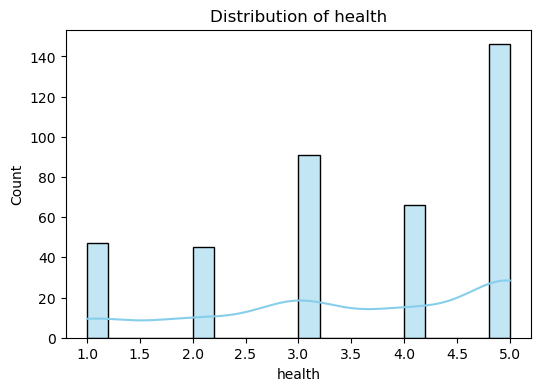

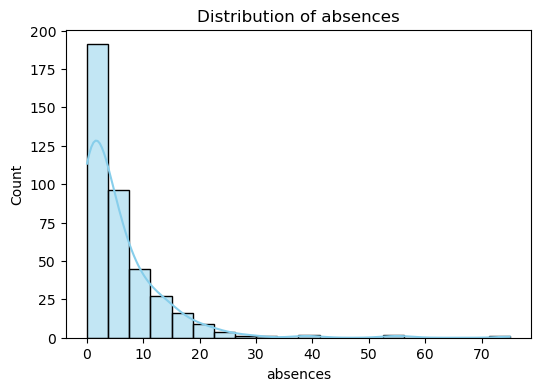

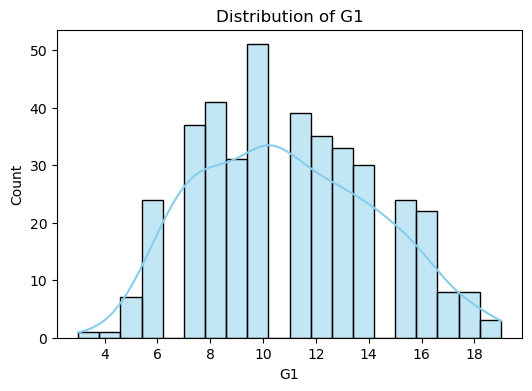

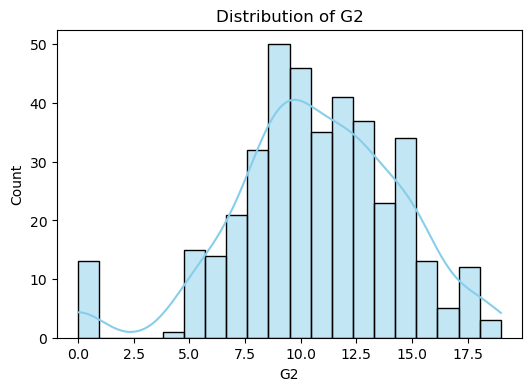

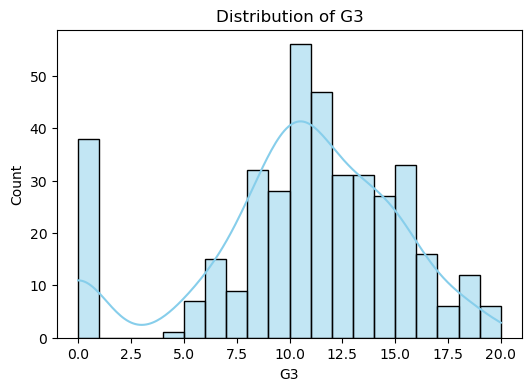

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Separate categorical and numerical columns
categorical_cols = df.select_dtypes(include=['object']).columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

# --- Visualize categorical features ---
for col in categorical_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df, palette="Set2")
    plt.title(f"Countplot of {col}")
    plt.xticks(rotation=45)
    plt.show()

# --- Visualize numerical features ---
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=20, color="skyblue")
    plt.title(f"Distribution of {col}")
    plt.show()




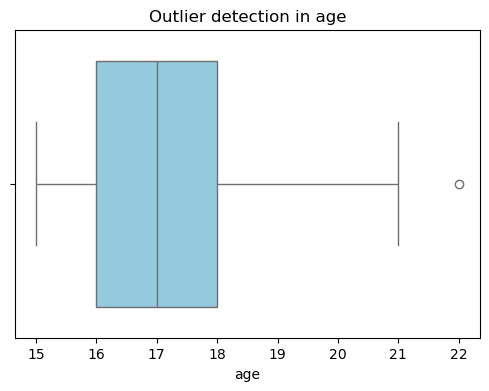

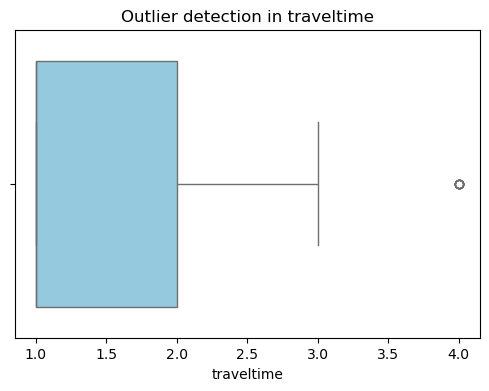

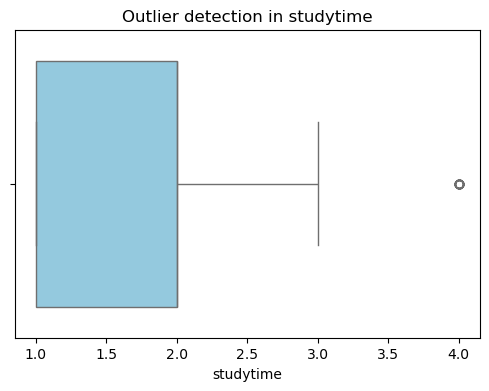

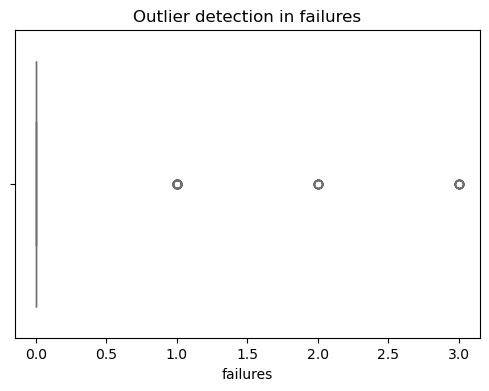

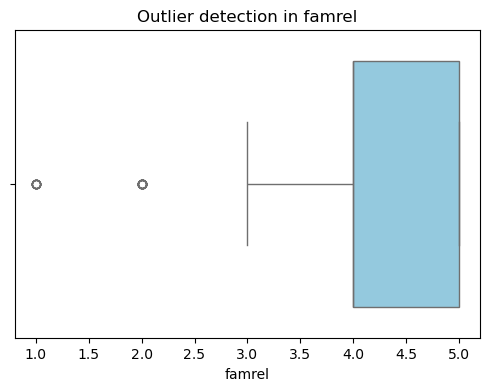

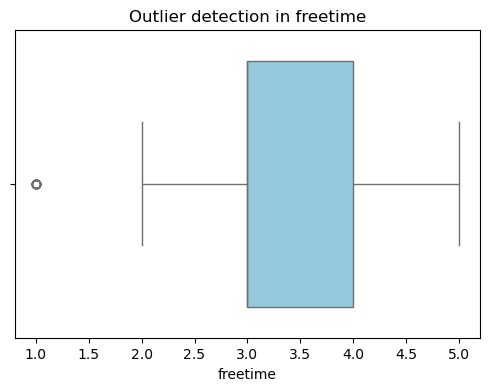

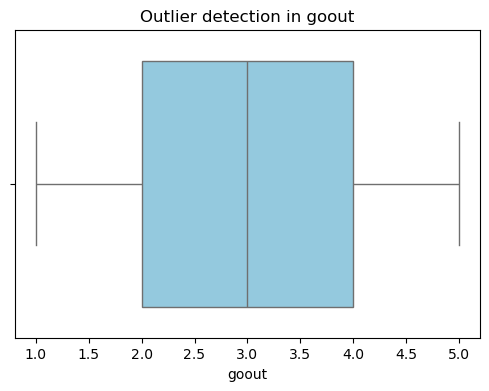

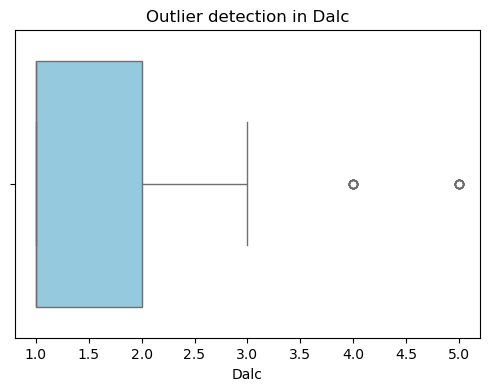

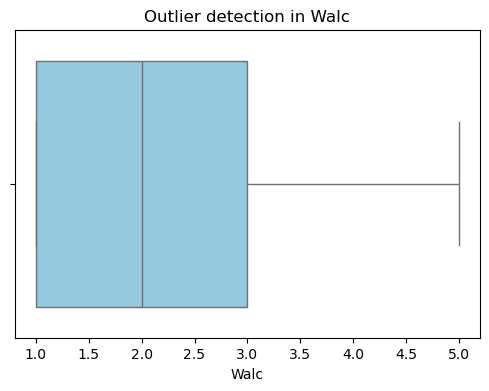

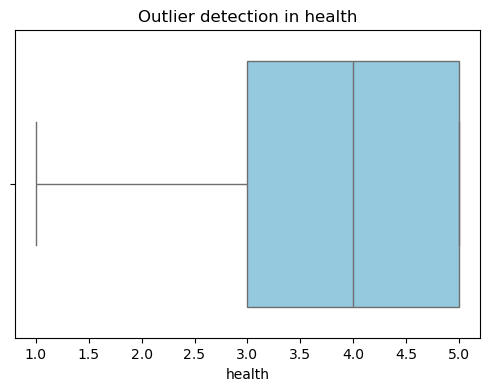

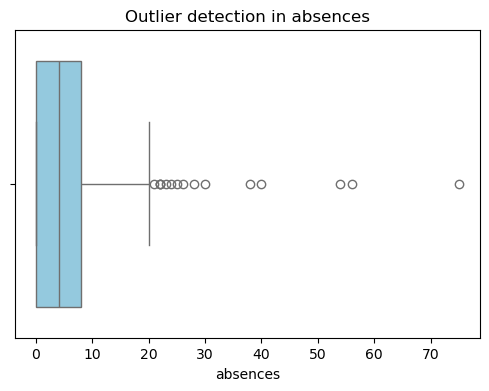

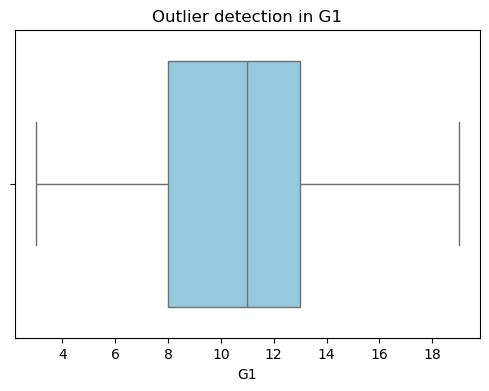

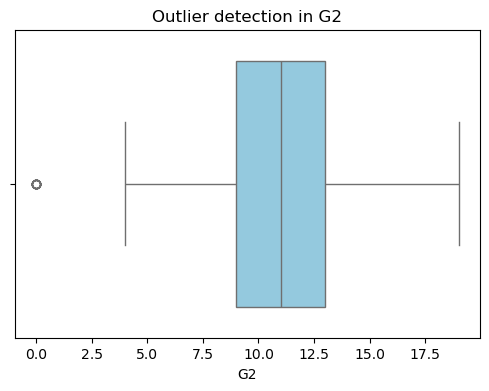

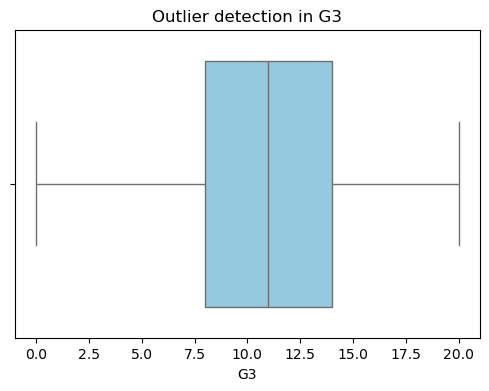

age: 1 outliers
traveltime: 8 outliers
studytime: 27 outliers
failures: 83 outliers
famrel: 26 outliers
freetime: 19 outliers
goout: 0 outliers
Dalc: 18 outliers
Walc: 0 outliers
health: 0 outliers
absences: 15 outliers
G1: 0 outliers
G2: 13 outliers
G3: 0 outliers


In [62]:

# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

# --- Detect outliers in numeric features using boxplots ---
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color="skyblue")
    plt.title(f"Outlier detection in {col}")
    plt.show()

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"{col}: {len(outliers)} outliers")


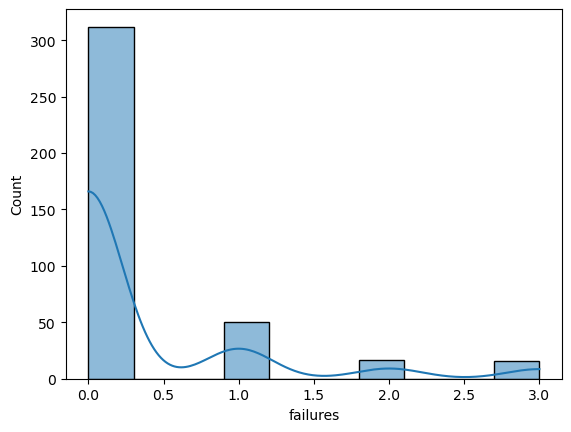

In [63]:
sns.histplot(df['failures'], bins=10, kde=True)
plt.show() # we can see most data is in 0 make it high in outliers